# Geometric seismic-wave inversion with boundary elements

This notebook implements the central idea of Bignardi, Fedele, Yezzi, Rix and Santarato, [*Geometric Seismic-Wave Inversion by the Boundary Element Method*](https://doi.org/10.1785/0120110091), *BSSA* 102(2), 2012. A known elastic layer overlies a known elastic half-space; the unknown is the **shape of their interface**. We predict complex, single-frequency horizontal and vertical displacements and adjust interface depths to fit them.

**Scope.** This is an independent educational implementation, not the authors' software or an exact reproduction of their figures. The inversion uses coupled 2D plane-strain elasticity and constant straight boundary elements rather than the paper's quadratic elements, one interface rather than multiple layers, and a finite truncated boundary. The target curve below is an approximation inspired by Fig. 1, not the original numerical data. Depth is positive downwards. See the final section for further limitations.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

from geometric_bem import (
    ElasticMedium, InversionOptions, TwoLayerBEM,
    invert_interface, perturb_measurements,
)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
np.set_printoptions(precision=3, suppress=True)

## 1. Forward model: coupled P-SV elastic waves

In each homogeneous region, the displacement satisfies the frequency-domain Navier equation

$$\mu\nabla^2\mathbf u+(\lambda+\mu)\nabla(\nabla\!\cdot\!\mathbf u)+\rho\omega^2\mathbf u=0.$$

The implementation uses the outgoing 2D full-space elastodynamic Green tensor, with both P- and S-wave wavenumbers. We use the $e^{-i\omega t}$ convention and complex elastic moduli for 5% damping. On the flat free surface, traction is zero except for a finite vertical source patch; across the interface, both displacement and traction are continuous.

The solver uses an **indirect single-layer BEM**. If $S_s^j$ and $S_i^j$ integrate the Green tensor of material $j$ over the surface and interface, it represents the fields as $\mathbf u_1=S_s^1\mathbf p+S_i^1\mathbf q$ and $\mathbf u_2=S_s^2\mathbf p+S_i^2\mathbf r$. The densities $\mathbf p,\mathbf q,\mathbf r$ are fictitious forces, not the physical boundary tractions. Collocation enforces the surface load and interface matching. Logarithmic self terms are integrated separately; the traction limits include their $\pm\tfrac12$ jump terms. See [geometric_bem.py](./geometric_bem.py) for the kernel and assembly.

## 2. Inverse model: deform the interface

Let $h_i$ be the depth at fixed horizontal coordinate $x_i$. We normalize the complex displacement residual by the norm of the selected observations and stack its real and imaginary parts into a real vector $r(h)$. Our discrete version of the paper's data misfit plus arc-length regularizer is

$$\Phi(h)=\tfrac12\|r(h)\|^2+\alpha\sum_i\left[\sqrt{(x_{i+1}-x_i)^2+(h_{i+1}-h_i)^2}-(x_{i+1}-x_i)\right].$$

The constant subtracted from the length does not change its derivatives. Central finite differences give $J=\partial r/\partial h$. With $g_L$ and $H_L$ the exact gradient and Hessian of this piecewise-linear length, one damped Gauss-Newton step solves

$$(J^\mathsf{T}J+\alpha H_L+\beta I)\,\Delta h=-(J^\mathsf{T}r+\alpha g_L).$$

As in the paper, regularization decreases from coarse to fine and $\beta$ limits unstable updates. Here $\alpha$ follows a geometric schedule; we also cap steps, bound depths and backtrack against the current objective. Since our residual is normalized, these weights are not numerically comparable to the paper's. The code reports if the iteration limit or line search is reached.

## 3. Synthetic experiment

We retain the paper's high- and low-contrast material values, seven receivers spaced 4 m apart, a source 3 m from the nearest receiver, a 25 m-deep initial interface, and angular frequency $\omega=1$ rad/s. Our 2 m-wide source patch has a total vertical force of 1000 N per metre of out-of-plane length. Unlike the paper's 33 interface nodes, this demonstration estimates nine depths and takes 25 iterations. The endpoints are extended horizontally to the truncated model boundaries.

In [2]:
control_x = np.linspace(-30.0, 0.0, 9)
receiver_x = np.array([-26., -22., -18., -14., -10., -6., -2.])
source_x, omega = 1.0, 1.0
upper = ElasticMedium(vp=500, vs=150, density=1600, damping=0.05)
high_lower = ElasticMedium(vp=2000, vs=800, density=2200, damping=0.05)
low_lower = ElasticMedium(vp=1000, vs=250, density=2000, damping=0.05)

central_surface = np.r_[[-29.0], np.arange(-27.0, 0.0, 2.0), [0.0, 2.0, 4.0]]
left = np.arange(-120.0, -30.0, 20.0)
right = np.arange(10.0, 121.0, 20.0)
surface_edges = np.r_[left, central_surface, right]
interface_x = np.r_[left, control_x, right]

target = np.interp(
    control_x, [-30, -25, -20, -16, -12, -6, 0],
    [10, 10, 7.5, 11, 15, 20, 22],
)
initial = np.full_like(control_x, 25.0)
options = InversionOptions(max_iterations=25, alpha_start=1e-3, alpha_end=1e-6,
                           damping=1e-5, max_step=2.0)

with threadpool_limits(limits=1, user_api='blas'):
    high_model = TwoLayerBEM(surface_edges, interface_x, control_x, receiver_x,
                             source_x, upper, high_lower, omega)
    low_model = TwoLayerBEM(surface_edges, interface_x, control_x, receiver_x,
                            source_x, upper, low_lower, omega)
    clean_data = high_model.predict(target)
    low_data = low_model.predict(target)

print(f'{len(receiver_x)} receivers, {len(control_x)} interface parameters')
print(f'Upper/lower high-contrast Vs: {upper.vs:g}/{high_lower.vs:g} m/s')
print(f'Frequency: {omega:g} rad/s ({omega / (2*np.pi):.3f} Hz)')

7 receivers, 9 interface parameters
Upper/lower high-contrast Vs: 150/800 m/s
Frequency: 1 rad/s (0.159 Hz)


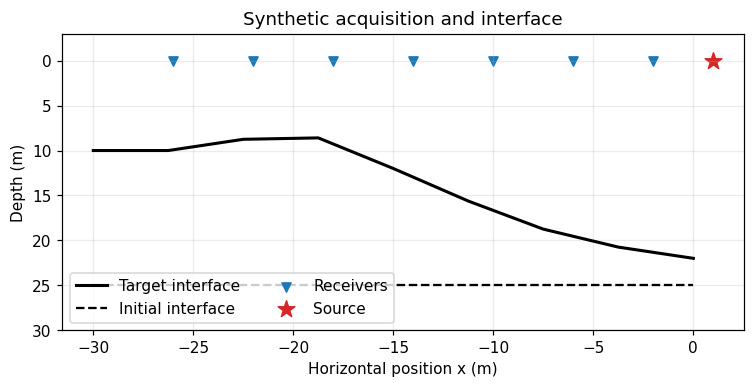

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(control_x, target, 'k-', lw=2, label='Target interface')
ax.plot(control_x, initial, 'k--', label='Initial interface')
ax.scatter(receiver_x, np.zeros_like(receiver_x), marker='v', color='tab:blue', label='Receivers')
ax.scatter([source_x], [0], marker='*', s=130, color='tab:red', label='Source')
ax.set(xlabel='Horizontal position x (m)', ylabel='Depth (m)', ylim=(30, -3),
       title='Synthetic acquisition and interface')
ax.legend(ncol=2, loc='lower left')
plt.show()

### Discretization check and synthetic-data caveat

The initial clean experiment uses the *same* forward discretization to create and fit the observations. This is an **inverse crime**, useful for checking the optimizer but optimistic about accuracy. We also create observations with twice as many central interface panels and a longer boundary, then invert them with the original model. This checks sensitivity to one change in discretization, not independence from the assumed physics or a complete convergence study.

In [4]:
fine_left = np.arange(-240.0, -30.0, 20.0)
fine_right = np.arange(10.0, 241.0, 20.0)
fine_surface = np.r_[fine_left, central_surface, fine_right]
fine_interface = np.r_[fine_left, np.linspace(-30.0, 0.0, 17), fine_right]
with threadpool_limits(limits=1, user_api='blas'):
    fine_model = TwoLayerBEM(fine_surface, fine_interface, control_x, receiver_x,
                             source_x, upper, high_lower, omega)
    fine_data = fine_model.predict(target)
mesh_difference = np.linalg.norm(clean_data - fine_data) / np.linalg.norm(fine_data)
print(f'Coarse versus refined/extended data at the target: {100*mesh_difference:.3f}% relative difference')

Coarse versus refined/extended data at the target: 0.225% relative difference


## 4. Noiseless reconstruction

Each iteration requires two forward solves per interface parameter for the central-difference Jacobian, plus a trial solve. The first run may take tens of seconds. The line-search status and final update are shown rather than treating an iteration limit as convergence.

In [5]:
with threadpool_limits(limits=1, user_api='blas'):
    clean_result = invert_interface(high_model, clean_data, initial, options)
if clean_result.reason.startswith('line search failed'):
    raise RuntimeError(clean_result.reason)
clean_rmse = np.sqrt(np.mean((clean_result.depths - target)**2))
initial_rmse = np.sqrt(np.mean((initial - target)**2))
print(f'Status: {clean_result.reason}; iterations: {clean_result.history[-1].iteration}')
print(f'Depth RMSE: {initial_rmse:.3f} m initially -> {clean_rmse:.3f} m')
print(f'Relative displacement misfit: {clean_result.history[0].relative_misfit:.4f} -> '
      f'{clean_result.history[-1].relative_misfit:.4f}')
print(f'Last maximum depth update: {clean_result.history[-1].max_update:.4f} m')

Status: maximum iterations reached; iterations: 25
Depth RMSE: 12.047 m initially -> 0.202 m
Relative displacement misfit: 0.4295 -> 0.0004
Last maximum depth update: 0.0269 m


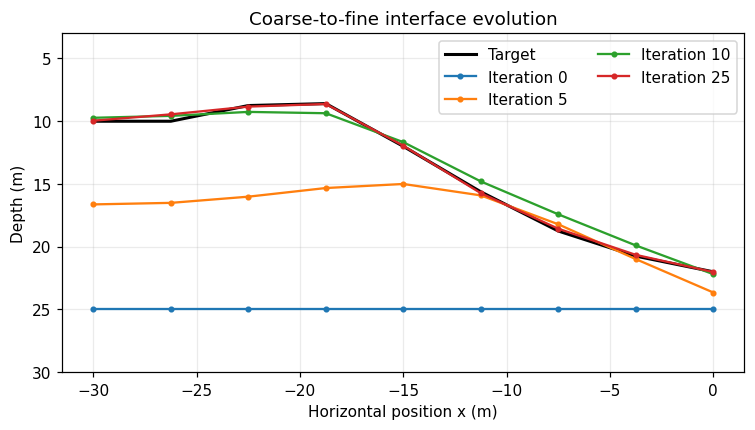

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(control_x, target, 'k-', lw=2, label='Target')
for index in [0, 5, 10, len(clean_result.history) - 1]:
    step = clean_result.history[index]
    ax.plot(control_x, step.depths, marker='o', ms=3, label=f'Iteration {step.iteration}')
ax.set(xlabel='Horizontal position x (m)', ylabel='Depth (m)', ylim=(30, 3),
       title='Coarse-to-fine interface evolution')
ax.legend(ncol=2)
plt.show()

## 5. Noise, receiver components, contrast and mesh mismatch

Following the paper's noise convention, independent Gaussian perturbations have $\sigma=(0.05/3)Q_{\max}$, calculated separately for each displacement component. Amplitude-only noise changes magnitudes but not phases; phase-only noise changes phases in radians but not magnitudes. These are **one seeded realization**, not a statistical study. We also fit vertical displacements alone, repeat the clean experiment with the paper's lower-contrast material, and fit the refined-mesh observations. Running all five additional cases may take a few minutes.

In [7]:
rng = np.random.default_rng(2026)
amplitude_data = perturb_measurements(clean_data, 0.05, 'amplitude', rng)
phase_data = perturb_measurements(clean_data, 0.05, 'phase', rng)

cases = {
    'Both, clean': (high_model, clean_data, (0, 1), clean_data),
    'Amplitude noise': (high_model, amplitude_data, (0, 1), clean_data),
    'Phase noise': (high_model, phase_data, (0, 1), clean_data),
    'Vertical only': (high_model, clean_data, (1,), clean_data),
    'Low contrast': (low_model, low_data, (0, 1), low_data),
    'Refined-mesh data': (high_model, fine_data, (0, 1), fine_data),
}
results = {'Both, clean': clean_result}
with threadpool_limits(limits=1, user_api='blas'):
    for label, (model, data, components, _) in list(cases.items())[1:]:
        print(f'Running {label}...', flush=True)
        result = invert_interface(model, data, initial, options, components=components)
        if result.reason.startswith('line search failed'):
            raise RuntimeError(f'{label}: {result.reason}')
        results[label] = result
        print(f'  {result.reason}; {result.history[-1].iteration} iterations', flush=True)

Running Amplitude noise...


  maximum iterations reached; 25 iterations


Running Phase noise...


  maximum iterations reached; 25 iterations


Running Vertical only...


  maximum iterations reached; 25 iterations


Running Low contrast...


  maximum iterations reached; 25 iterations


Running Refined-mesh data...


  maximum iterations reached; 25 iterations


### Quantitative comparison

Depth RMSE uses the known synthetic target. Relative fit error is computed **only over the components used by that inversion**, divided by the norm of its input data. The last column compares the same components with the corresponding noise-free data (or with the refined data in that experiment). Consequently, fit errors from vertical-only and two-component experiments do not use the same set of measurements.

In [8]:
def depth_rmse(result):
    return float(np.sqrt(np.mean((result.depths - target)**2)))

def relative_error(prediction, reference, components):
    return float(np.linalg.norm((prediction - reference)[:, components]) /
                 np.linalg.norm(reference[:, components]))

rows = ['| Experiment | Depth RMSE (m) | Fit error (%) | Error against reference (%) |',
        '|:--|--:|--:|--:|']
for label, (_, observed, components, reference) in cases.items():
    result = results[label]
    fit = relative_error(result.predicted, observed, components)
    reference_error = relative_error(result.predicted, reference, components)
    rows.append(f'| {label} | {depth_rmse(result):.3f} | {100*fit:.3f} | {100*reference_error:.3f} |')
display(Markdown('\n'.join(rows)))

| Experiment | Depth RMSE (m) | Fit error (%) | Error against reference (%) |
|:--|--:|--:|--:|
| Both, clean | 0.202 | 0.042 | 0.042 |
| Amplitude noise | 1.828 | 2.077 | 1.271 |
| Phase noise | 0.369 | 3.621 | 0.246 |
| Vertical only | 0.937 | 0.029 | 0.029 |
| Low contrast | 0.733 | 0.165 | 0.165 |
| Refined-mesh data | 0.216 | 0.131 | 0.131 |

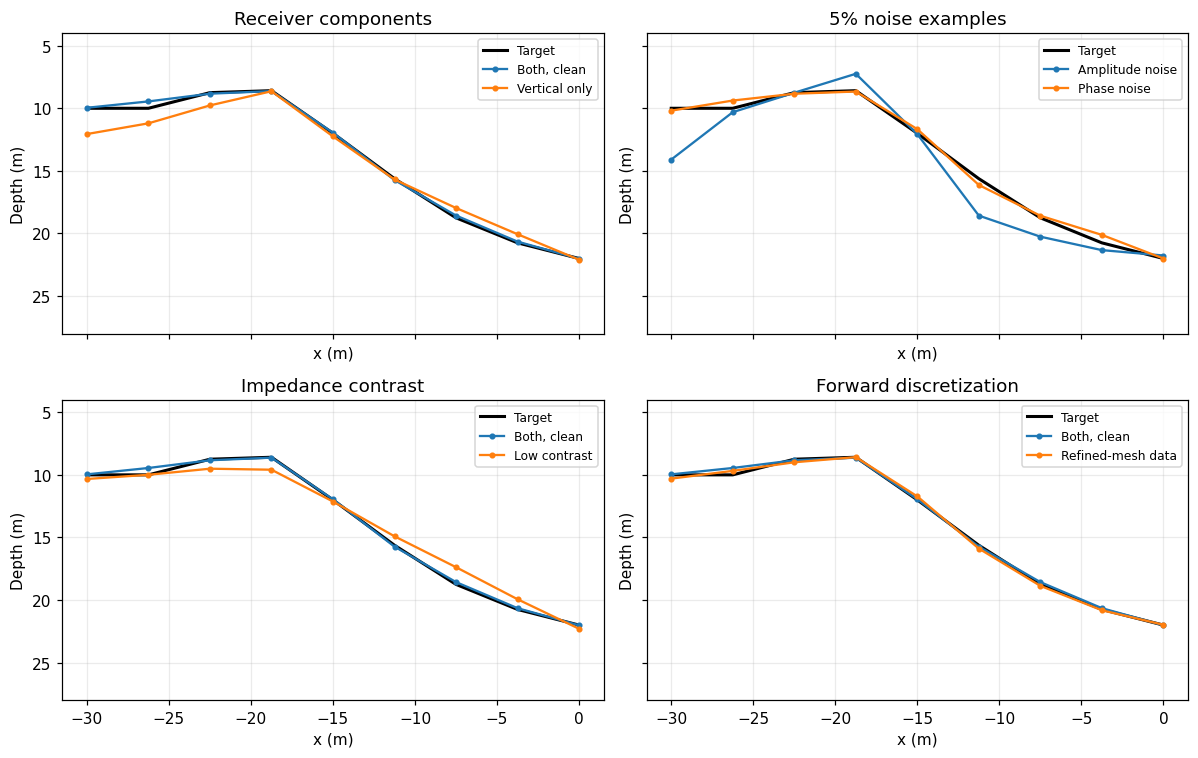

In [9]:
panels = [
    ('Receiver components', 'Both, clean', 'Vertical only'),
    ('5% noise examples', 'Amplitude noise', 'Phase noise'),
    ('Impedance contrast', 'Both, clean', 'Low contrast'),
    ('Forward discretization', 'Both, clean', 'Refined-mesh data'),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (title, first, second) in zip(axes.flat, panels):
    ax.plot(control_x, target, 'k-', lw=2, label='Target')
    for label in (first, second):
        ax.plot(control_x, results[label].depths, marker='o', ms=3, label=label)
    ax.set(title=title, xlabel='x (m)', ylabel='Depth (m)', ylim=(28, 4))
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

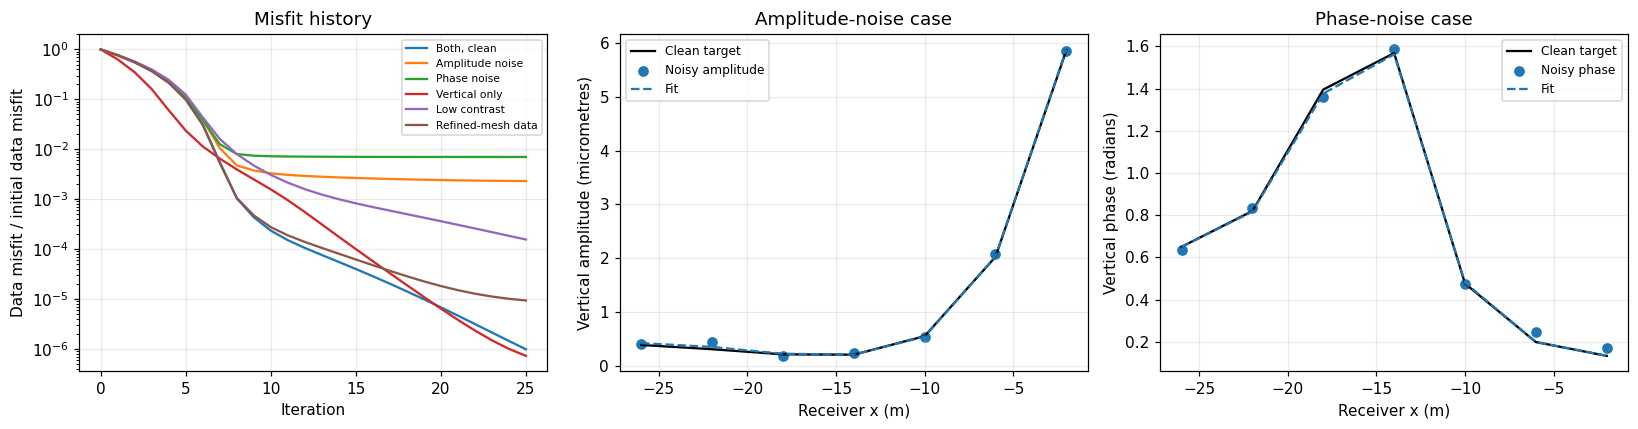

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for label, result in results.items():
    history = result.history
    relative_energy = [(step.relative_misfit / history[0].relative_misfit)**2 for step in history]
    axes[0].semilogy([step.iteration for step in history], relative_energy, label=label)
axes[0].set(xlabel='Iteration', ylabel='Data misfit / initial data misfit', title='Misfit history')
axes[0].legend(fontsize=7)

axes[1].plot(receiver_x, 1e6*np.abs(clean_data[:, 1]), 'k-', label='Clean target')
axes[1].scatter(receiver_x, 1e6*np.abs(amplitude_data[:, 1]), label='Noisy amplitude')
axes[1].plot(receiver_x, 1e6*np.abs(results['Amplitude noise'].predicted[:, 1]), '--', label='Fit')
axes[1].set(xlabel='Receiver x (m)', ylabel='Vertical amplitude (micrometres)', title='Amplitude-noise case')
axes[1].legend(fontsize=8)

axes[2].plot(receiver_x, np.unwrap(np.angle(clean_data[:, 1])), 'k-', label='Clean target')
axes[2].scatter(receiver_x, np.unwrap(np.angle(phase_data[:, 1])), label='Noisy phase')
axes[2].plot(receiver_x, np.unwrap(np.angle(results['Phase noise'].predicted[:, 1])), '--', label='Fit')
axes[2].set(xlabel='Receiver x (m)', ylabel='Vertical phase (radians)', title='Phase-noise case')
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [11]:
amp_rmse = depth_rmse(results['Amplitude noise'])
phase_rmse = depth_rmse(results['Phase noise'])
more_affected = 'amplitude' if amp_rmse > phase_rmse else 'phase'
display(Markdown(f'''
## 6. Interpreting this run

* For the same-mesh noiseless problem, depth RMSE fell from **{initial_rmse:.2f} m** to **{clean_rmse:.2f} m**. This demonstrates that the implemented update can fit this synthetic setup, not that it uniquely recovers a real subsurface.
* The vertical-only reconstruction has **{depth_rmse(results['Vertical only']):.2f} m** depth RMSE. A small waveform residual alone does not guarantee a unique or accurate interface, especially with fewer measured components.
* For this particular seed, **{more_affected}-only noise** produced the larger depth error: amplitude **{amp_rmse:.2f} m**, phase **{phase_rmse:.2f} m**. The paper reported greater sensitivity to phase noise for its examples. A single draw with a different discretization, target and optimizer cannot establish a general ranking; repeated seeds would be needed.
* The lower-contrast clean case has **{depth_rmse(results['Low contrast']):.2f} m** RMSE. For the refined/extended synthetic data, the coarse model's RMSE is **{depth_rmse(results['Refined-mesh data']):.2f} m**, and the two forward data sets differ by **{100*mesh_difference:.3f}%** at the target.

All cases above report their actual stop reason. Reaching the iteration limit is not a convergence certificate.
'''))


## 6. Interpreting this run

* For the same-mesh noiseless problem, depth RMSE fell from **12.05 m** to **0.20 m**. This demonstrates that the implemented update can fit this synthetic setup, not that it uniquely recovers a real subsurface.
* The vertical-only reconstruction has **0.94 m** depth RMSE. A small waveform residual alone does not guarantee a unique or accurate interface, especially with fewer measured components.
* For this particular seed, **amplitude-only noise** produced the larger depth error: amplitude **1.83 m**, phase **0.37 m**. The paper reported greater sensitivity to phase noise for its examples. A single draw with a different discretization, target and optimizer cannot establish a general ranking; repeated seeds would be needed.
* The lower-contrast clean case has **0.73 m** RMSE. For the refined/extended synthetic data, the coarse model's RMSE is **0.22 m**, and the two forward data sets differ by **0.225%** at the target.

All cases above report their actual stop reason. Reaching the iteration limit is not a convergence certificate.


## 7. Pressurized-cylinder benchmark (paper Fig. 2)

For an infinitely long cylinder under uniform inward pressure, the plane-strain radial displacement is proportional to $J_1(k_p r)$. At radius $a$ the analytic boundary displacement is

$$u_r(a)=\frac{-p J_1(k_p a)}{(\lambda+2\mu)k_p J_0(k_p a)-2\mu J_1(k_p a)/a}.$$

We use the paper's $a=6$ m, $\rho=100$ kg/m³, $\mu=10^6$ Pa, $\nu=0.25$ and 5% damping. The proof prints a normal load of $100^2$ N/m² (10,000 Pa), but its plotted displacement scale corresponds to about **100 Pa** with the stated material parameters. We use 100 Pa to match the plotted scale; if the printed load is literal, the displacements are 100 times larger while the resonance and relative errors are unchanged.

The first *undamped* radial resonance is computed from the zero of the denominator. The BEM curves below use exact circular arcs. **Constant vector densities** are a general collocation approximation; the **radial basis** additionally exploits the known rotational symmetry of this special benchmark. The latter is not the paper's quadratic-element method and is not an independent validation of the whole inversion.

First undamped radial frequency: 59.738 rad/s (paper: 59.73 rad/s)
Constant vector,  8 elements: relative complex error at resonance = 37.9809%
Constant vector, 32 elements: relative complex error at resonance = 9.2440%
Symmetry-based radial,  8 elements: relative complex error at resonance = 0.0022%
Symmetry-based radial, 32 elements: relative complex error at resonance = 0.0005%


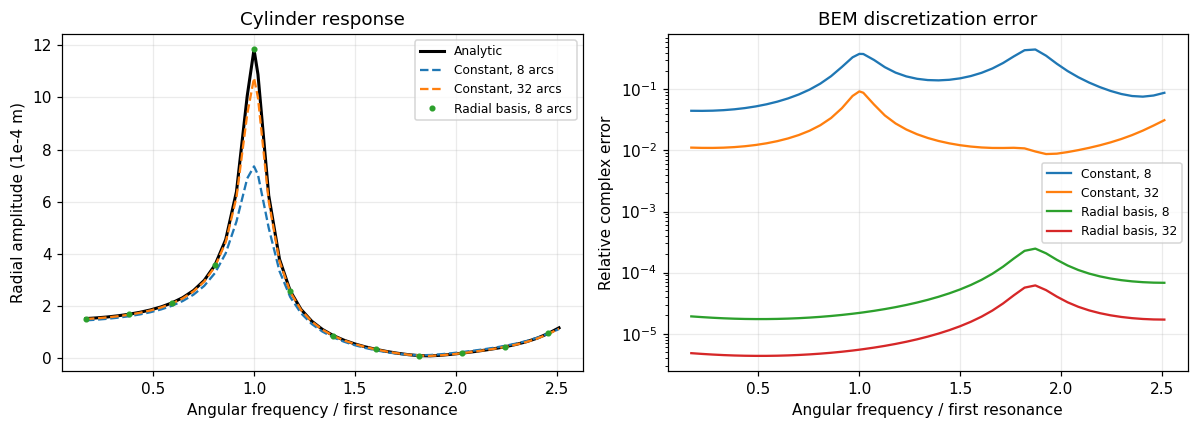

In [12]:
from cylinder_bem import (cylinder_analytic, cylinder_axisymmetric_bem,
                          cylinder_bem, cylinder_first_frequency)

cylinder_material = ElasticMedium(vp=np.sqrt(30000), vs=100, density=100, damping=0.05)
radius, pressure = 6.0, 100.0
omega1 = cylinder_first_frequency(radius, cylinder_material)
frequencies = np.unique(np.r_[np.linspace(10.0, 150.0, 45), omega1])
with threadpool_limits(limits=1, user_api='blas'):
    analytical = np.array([cylinder_analytic(radius, w, cylinder_material, pressure) for w in frequencies])
    constant = {n: np.array([cylinder_bem(radius, w, cylinder_material, pressure, elements=n)
                             for w in frequencies]) for n in (8, 32)}
    radial = {n: np.array([cylinder_axisymmetric_bem(radius, w, cylinder_material, pressure, elements=n)
                           for w in frequencies]) for n in (8, 32)}
peak_index = np.argmin(np.abs(frequencies - omega1))
print(f'First undamped radial frequency: {omega1:.3f} rad/s (paper: 59.73 rad/s)')
for label, curves in [('Constant vector', constant), ('Symmetry-based radial', radial)]:
    for n, curve in curves.items():
        error = abs(curve[peak_index] - analytical[peak_index]) / abs(analytical[peak_index])
        print(f'{label}, {n:2d} elements: relative complex error at resonance = {100*error:.4f}%')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(frequencies / omega1, np.abs(analytical)*1e4, 'k-', lw=2, label='Analytic')
for n in (8, 32):
    axes[0].plot(frequencies / omega1, np.abs(constant[n])*1e4, '--', label=f'Constant, {n} arcs')
axes[0].plot(frequencies / omega1, np.abs(radial[8])*1e4, 'o', ms=3, markevery=4, label='Radial basis, 8 arcs')
axes[0].set(xlabel='Angular frequency / first resonance', ylabel='Radial amplitude (1e-4 m)', title='Cylinder response')
axes[0].legend(fontsize=8)
for label, curves in [('Constant', constant), ('Radial basis', radial)]:
    for n, curve in curves.items():
        axes[1].semilogy(frequencies / omega1, np.abs(curve-analytical)/np.abs(analytical), label=f'{label}, {n}')
axes[1].set(xlabel='Angular frequency / first resonance', ylabel='Relative complex error', title='BEM discretization error')
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 8. More synthetic cases: Figs. 4–7

The earlier examples covered Fig. 3's high-contrast, two-component noise cases. We now add the missing 5% amplitude/phase cases for **vertical-only** high-contrast data (Fig. 4) and **both-component low-contrast** data (Fig. 5), plus 10% amplitude/phase noise for each contrast under a nonflat free surface (Figs. 6–7). The hill is a smooth approximation to the plotted topography, not the authors' coordinates. The source acts normal to the surface. For vertical-only data we use stronger damping and a slower regularization schedule, as suggested in the paper.

Each case uses one reproducible noise realization and the same forward discretization to generate and invert its data. It therefore remains an inverse crime. The field observations from Alabama are not supplied with the paper and are not simulated as if they were measured data.

In [13]:
def smoothstep(values):
    t = np.clip(values, 0, 1)
    return t*t*(3 - 2*t)

# Depth is positive downward, so a hill has negative surface depth.
topography = -5 * smoothstep((surface_edges + 25) / 6) * (1 - smoothstep((surface_edges + 10) / 6))
with threadpool_limits(limits=1, user_api='blas'):
    high_hill = TwoLayerBEM(surface_edges, interface_x, control_x, receiver_x, source_x,
                            upper, high_lower, omega, surface_depths=topography)
    low_hill = TwoLayerBEM(surface_edges, interface_x, control_x, receiver_x, source_x,
                           upper, low_lower, omega, surface_depths=topography)
    high_hill_data = high_hill.predict(target)
    low_hill_data = low_hill.predict(target)

def noisy_pair(data, level, seed):
    generator = np.random.default_rng(seed)
    return (perturb_measurements(data, level, 'amplitude', generator),
            perturb_measurements(data, level, 'phase', generator))

low_amplitude, low_phase = noisy_pair(low_data, 0.05, 2026)
hill_high_amplitude, hill_high_phase = noisy_pair(high_hill_data, 0.10, 42)
hill_low_amplitude, hill_low_phase = noisy_pair(low_hill_data, 0.10, 42)
vertical_options = InversionOptions(max_iterations=25, alpha_start=2e-3, alpha_end=1e-5,
                                    damping=4e-5, max_step=1.5)
expanded_cases = {
    'Vertical, amplitude 5%': (high_model, amplitude_data, (1,), clean_data, vertical_options),
    'Vertical, phase 5%': (high_model, phase_data, (1,), clean_data, vertical_options),
    'Low contrast, amplitude 5%': (low_model, low_amplitude, (0, 1), low_data, options),
    'Low contrast, phase 5%': (low_model, low_phase, (0, 1), low_data, options),
    'High hill, amplitude 10%': (high_hill, hill_high_amplitude, (0, 1), high_hill_data, options),
    'High hill, phase 10%': (high_hill, hill_high_phase, (0, 1), high_hill_data, options),
    'Low hill, amplitude 10%': (low_hill, hill_low_amplitude, (0, 1), low_hill_data, options),
    'Low hill, phase 10%': (low_hill, hill_low_phase, (0, 1), low_hill_data, options),
}
print(f'Hill height: {-topography.min():.1f} m; high-contrast waveform change vs. flat: '
      f'{100*np.linalg.norm(high_hill_data-clean_data)/np.linalg.norm(high_hill_data):.1f}%')

Hill height: 5.0 m; high-contrast waveform change vs. flat: 21.5%


In [14]:
expanded_results = {}
with threadpool_limits(limits=1, user_api='blas'):
    for label, (model, data, components, _, case_options) in expanded_cases.items():
        print(f'Running {label}...', flush=True)
        result = invert_interface(model, data, initial, case_options, components=components)
        if result.reason.startswith('line search failed'):
            raise RuntimeError(f'{label}: {result.reason}')
        expanded_results[label] = result
        print(f'  {result.reason}; {result.history[-1].iteration} iterations', flush=True)

Running Vertical, amplitude 5%...


  maximum iterations reached; 25 iterations


Running Vertical, phase 5%...


  maximum iterations reached; 25 iterations


Running Low contrast, amplitude 5%...


  maximum iterations reached; 25 iterations


... (6 outputs left out)

Running Low hill, amplitude 10%...


  maximum iterations reached; 25 iterations


Running Low hill, phase 10%...


  maximum iterations reached; 25 iterations


In [15]:
rows = ['| Experiment | Depth RMSE (m) | Max error / 15 m (%) | Fit error (%) | Final / initial misfit | Stop |',
        '|:--|--:|--:|--:|--:|:--|']
for label, (_, data, components, _, _) in expanded_cases.items():
    result = expanded_results[label]
    fit = relative_error(result.predicted, data, components)
    max_error = 100 * np.max(np.abs(result.depths - target)) / 15
    ratio = (result.history[-1].relative_misfit / result.history[0].relative_misfit)**2
    rows.append(f'| {label} | {depth_rmse(result):.2f} | {max_error:.1f} | {100*fit:.2f} | {ratio:.3g} | {result.reason} |')
display(Markdown('\n'.join(rows)))
display(Markdown('The 15 m denominator follows the paper; our target and discretization are approximate, '
                 'so these numbers are not a direct reproduction of its reported 1.2–8% range.'))

| Experiment | Depth RMSE (m) | Max error / 15 m (%) | Fit error (%) | Final / initial misfit | Stop |
|:--|--:|--:|--:|--:|:--|
| Vertical, amplitude 5% | 3.05 | 43.9 | 2.14 | 0.0039 | maximum iterations reached |
| Vertical, phase 5% | 3.38 | 47.4 | 3.62 | 0.011 | maximum iterations reached |
| Low contrast, amplitude 5% | 1.28 | 22.6 | 1.65 | 0.0153 | maximum iterations reached |
| Low contrast, phase 5% | 0.83 | 8.3 | 1.64 | 0.0146 | maximum iterations reached |
| High hill, amplitude 10% | 3.76 | 44.7 | 6.44 | 0.0296 | maximum iterations reached |
| High hill, phase 10% | 0.44 | 4.7 | 2.33 | 0.00337 | maximum iterations reached |
| Low hill, amplitude 10% | 2.53 | 27.0 | 5.30 | 0.19 | maximum iterations reached |
| Low hill, phase 10% | 1.22 | 13.5 | 1.21 | 0.0098 | maximum iterations reached |

The 15 m denominator follows the paper; our target and discretization are approximate, so these numbers are not a direct reproduction of its reported 1.2–8% range.

### Interpretation of the saved run

With 5% noise, the vertical-only examples have depth RMSEs of **3.05 m** (amplitude) and **3.38 m** (phase), even though their waveform fit errors are only 2.14% and 3.62%. With the high-contrast hill and 10% noise, the corresponding depth RMSEs are **3.76 m** and **0.44 m**. Fitting the data does not by itself guarantee an accurate interface; the chosen regularization schedules also differ between the vertical-only and two-component cases.

The largest separation reaches **47.4% of 15 m**, substantially above the paper's stated 1.2–8% range. The target geometry, numerical method, stopping rule and noise draws differ, so this is not a like-for-like comparison and does not isolate a single cause. All these cases reached the 25-iteration limit, rather than a convergence certificate. These numbers describe the saved default run and must be reinterpreted if its inputs change.

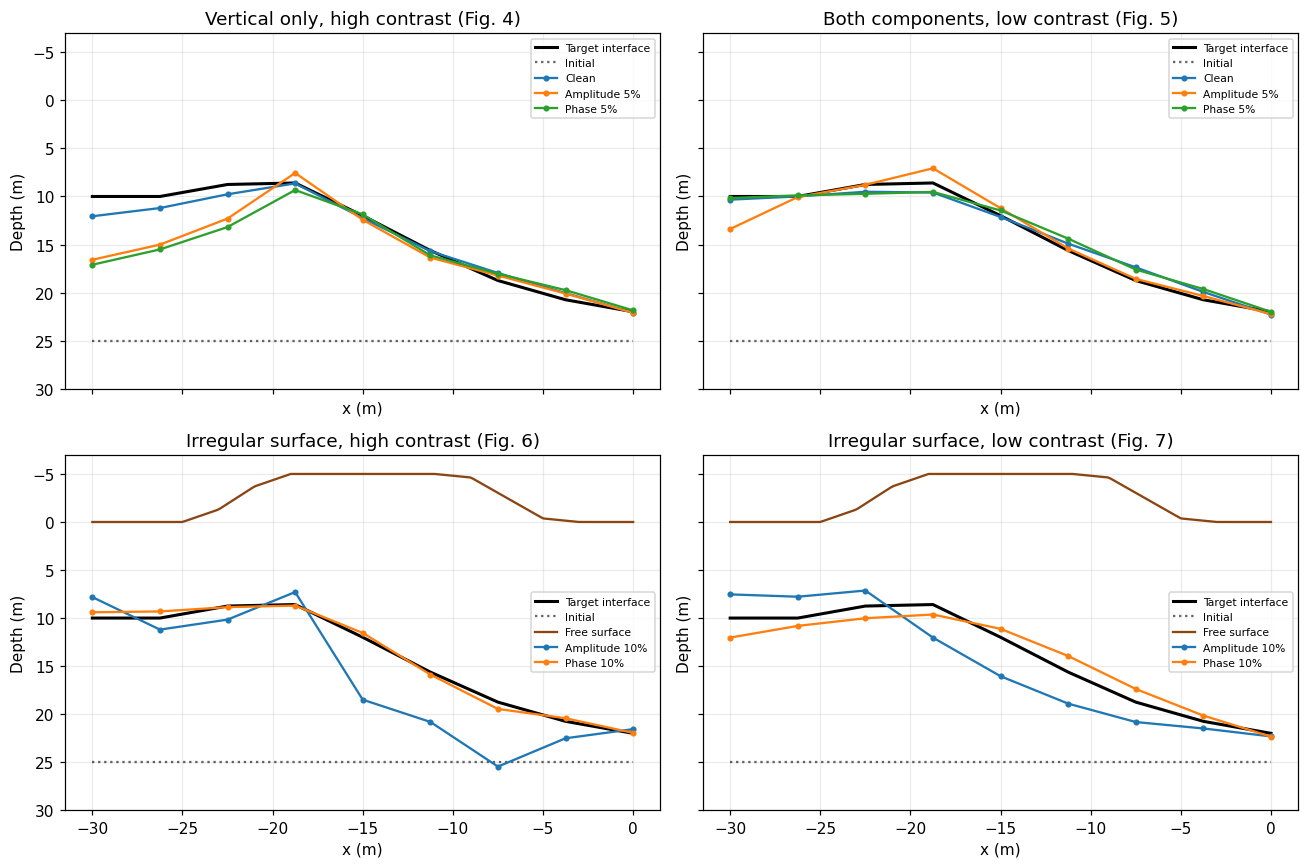

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
plot_cases = [
    ('Vertical only, high contrast (Fig. 4)', [('Clean', results['Vertical only']),
       ('Amplitude 5%', expanded_results['Vertical, amplitude 5%']), ('Phase 5%', expanded_results['Vertical, phase 5%'])], False),
    ('Both components, low contrast (Fig. 5)', [('Clean', results['Low contrast']),
       ('Amplitude 5%', expanded_results['Low contrast, amplitude 5%']), ('Phase 5%', expanded_results['Low contrast, phase 5%'])], False),
    ('Irregular surface, high contrast (Fig. 6)', [('Amplitude 10%', expanded_results['High hill, amplitude 10%']),
       ('Phase 10%', expanded_results['High hill, phase 10%'])], True),
    ('Irregular surface, low contrast (Fig. 7)', [('Amplitude 10%', expanded_results['Low hill, amplitude 10%']),
       ('Phase 10%', expanded_results['Low hill, phase 10%'])], True),
]
xx = np.linspace(-30, 0, 200)
for ax, (title, curves, show_hill) in zip(axes.flat, plot_cases):
    ax.plot(control_x, target, 'k-', lw=2, label='Target interface')
    ax.plot(control_x, initial, 'k:', alpha=.6, label='Initial')
    if show_hill:
        ax.plot(xx, np.interp(xx, surface_edges, topography), color='saddlebrown', label='Free surface')
    for label, result in curves:
        ax.plot(control_x, result.depths, marker='o', ms=3, label=label)
    ax.set(title=title, xlabel='x (m)', ylabel='Depth (m)', ylim=(30, -7))
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

### Normalized misfit histories

The right-hand panels of the paper's Figs. 4–7 show the data misfit $E/E_0$. The plots below use the squared relative residual divided by its initial value for each experiment. They cover at most 25 iterations, not the paper's longer runs; changing the regularization weight can make the data misfit nonmonotone.

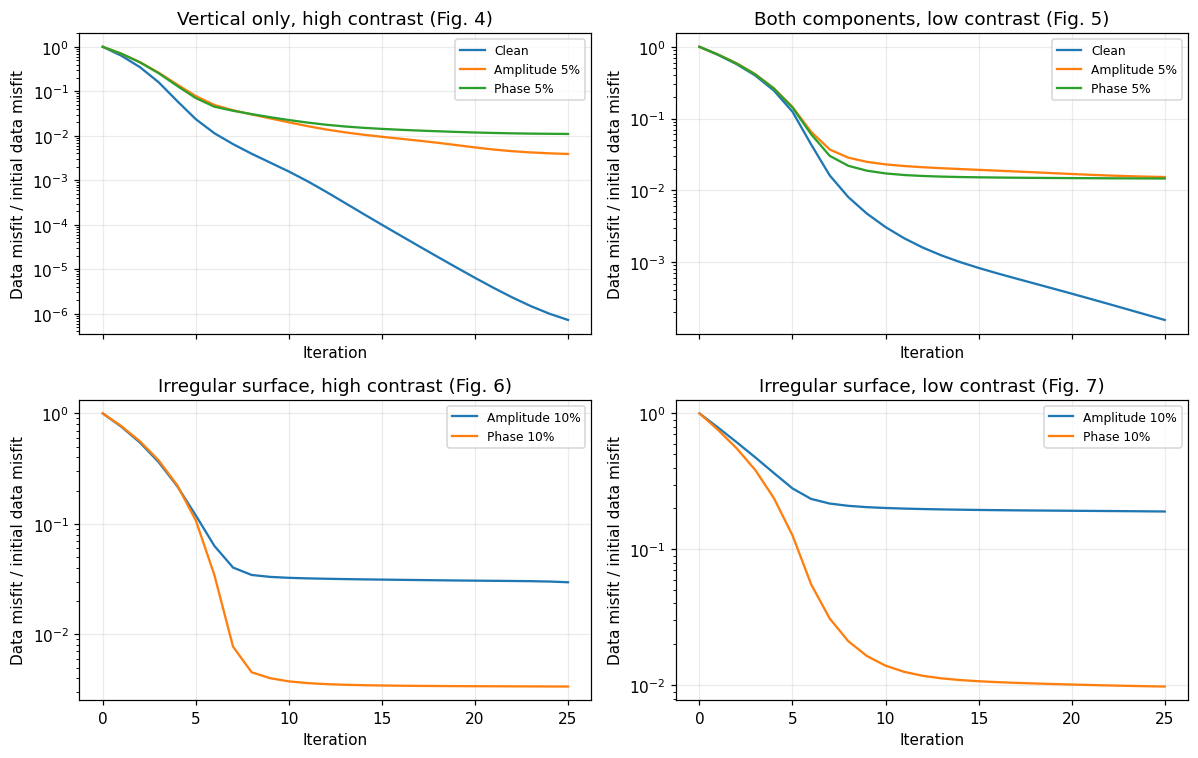

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, (title, curves, _) in zip(axes.flat, plot_cases):
    for label, result in curves:
        history = result.history
        normalized = [(step.relative_misfit / history[0].relative_misfit)**2 for step in history]
        ax.semilogy([step.iteration for step in history], normalized, label=label)
    ax.set(title=title, xlabel='Iteration', ylabel='Data misfit / initial data misfit')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Both displacement components (paper Fig. 8)

The plot compares modeled and synthetic noisy horizontal and vertical amplitudes/phases. Receivers are ordered from nearest to farthest from the source. Error bars show the **three-sigma noise scale used to generate these data**, not measured field uncertainty. The phase convention and geometry differ from the paper, so the plotted phases need not have the same signs.

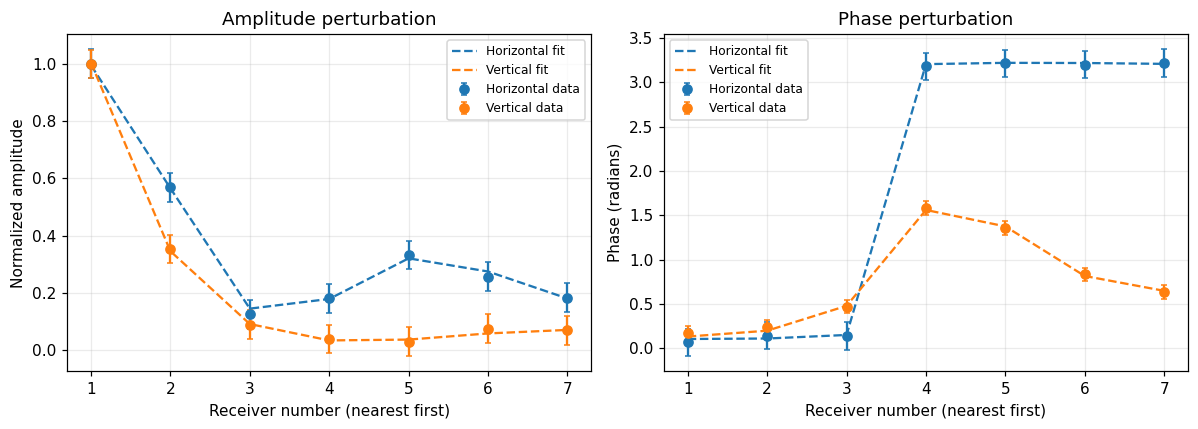

In [18]:
order = np.argsort(np.abs(receiver_x-source_x))
sensor = np.arange(1, len(receiver_x)+1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for component, label, color in [(0, 'Horizontal', 'tab:blue'), (1, 'Vertical', 'tab:orange')]:
    scale = np.max(np.abs(clean_data[:, component]))
    observed_amp = np.abs(amplitude_data[order, component]) / scale
    fitted_amp = np.abs(results['Amplitude noise'].predicted[order, component]) / scale
    axes[0].errorbar(sensor, observed_amp, yerr=0.05, fmt='o', color=color, capsize=2, label=f'{label} data')
    axes[0].plot(sensor, fitted_amp, '--', color=color, label=f'{label} fit')
    reference_phase = np.unwrap(np.angle(clean_data[order, component]))
    observed_phase = reference_phase + np.angle(phase_data[order, component] / clean_data[order, component])
    fitted_phase = reference_phase + np.angle(results['Phase noise'].predicted[order, component] / clean_data[order, component])
    phase_band = 0.05 * np.max(np.abs(np.angle(clean_data[:, component])))
    axes[1].errorbar(sensor, observed_phase, yerr=phase_band, fmt='o', color=color, capsize=2, label=f'{label} data')
    axes[1].plot(sensor, fitted_phase, '--', color=color, label=f'{label} fit')
axes[0].set(xlabel='Receiver number (nearest first)', ylabel='Normalized amplitude', title='Amplitude perturbation')
axes[1].set(xlabel='Receiver number (nearest first)', ylabel='Phase (radians)', title='Phase perturbation')
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 9. Thirty-three interface parameters

The paper estimates 33 interface nodes from seven two-component complex observations. We now use 33 depths and start from the same flat 25 m guess. Seven complex two-component recordings contain at most 28 real numbers, so the linearized inverse problem has at least five unobservable directions before regularization. To keep this notebook practical we take only 15 capped Gauss-Newton iterations, not the paper's approximately 1500 iterations, and use constant rather than quadratic elements. The target is the same approximate piecewise-linear curve sampled at 33 nodes; data are again generated and fitted on the same mesh.

33 depths, 14 complex measurements = 28 real values
Status: maximum iterations reached; last maximum update: 0.074 m
Depth RMSE: 12.121 -> 0.427 m
Relative displacement misfit: 0.42934 -> 0.00194


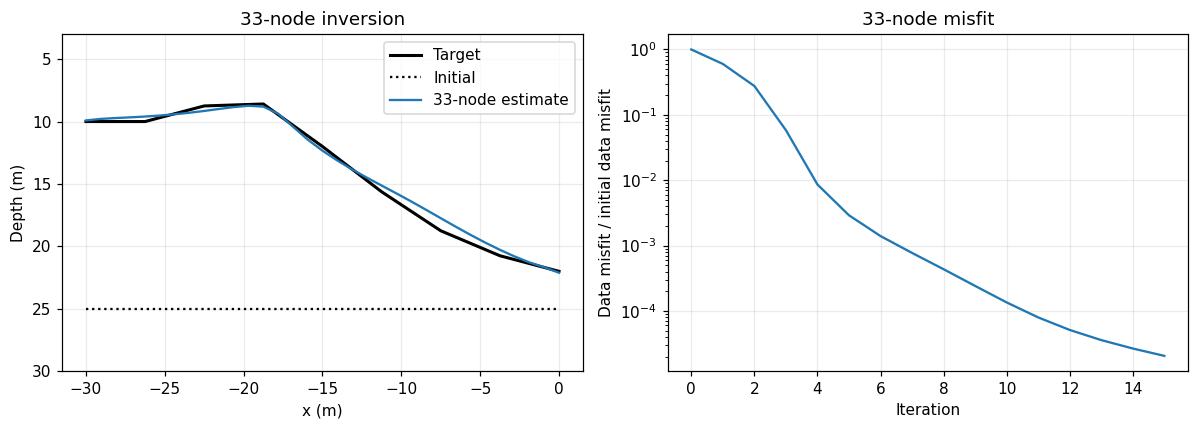

In [19]:
x33 = np.linspace(-30, 0, 33)
target33 = np.interp(x33, control_x, target)
initial33 = np.full_like(x33, 25.0)
options33 = InversionOptions(max_iterations=15, alpha_start=1e-2, alpha_end=1e-6,
                             damping=1e-5, max_step=4.0)
with threadpool_limits(limits=1, user_api='blas'):
    model33 = TwoLayerBEM(surface_edges, np.r_[left, x33, right], x33, receiver_x,
                          source_x, upper, high_lower, omega)
    data33 = model33.predict(target33)
    result33 = invert_interface(model33, data33, initial33, options33)
if result33.reason.startswith('line search failed'):
    raise RuntimeError(result33.reason)
initial33_error = np.sqrt(np.mean((initial33-target33)**2))
final33_error = np.sqrt(np.mean((result33.depths-target33)**2))
print(f'33 depths, {data33.size} complex measurements = {2*data33.size} real values')
print(f'Status: {result33.reason}; last maximum update: {result33.history[-1].max_update:.3f} m')
print(f'Depth RMSE: {initial33_error:.3f} -> {final33_error:.3f} m')
print(f'Relative displacement misfit: {result33.history[0].relative_misfit:.5f} -> '
      f'{result33.history[-1].relative_misfit:.5f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x33, target33, 'k-', lw=2, label='Target')
axes[0].plot(x33, initial33, 'k:', label='Initial')
axes[0].plot(x33, result33.depths, label='33-node estimate')
axes[0].set(xlabel='x (m)', ylabel='Depth (m)', ylim=(30, 3), title='33-node inversion')
axes[0].legend()
history33 = result33.history
axes[1].semilogy([step.iteration for step in history33],
                 [(step.relative_misfit/history33[0].relative_misfit)**2 for step in history33])
axes[1].set(xlabel='Iteration', ylabel='Data misfit / initial data misfit', title='33-node misfit')
fig.tight_layout()
plt.show()

Jacobian shape (28, 33): at least 5 null directions
Singular values above 1e-6 of the largest: 19 (threshold-dependent)


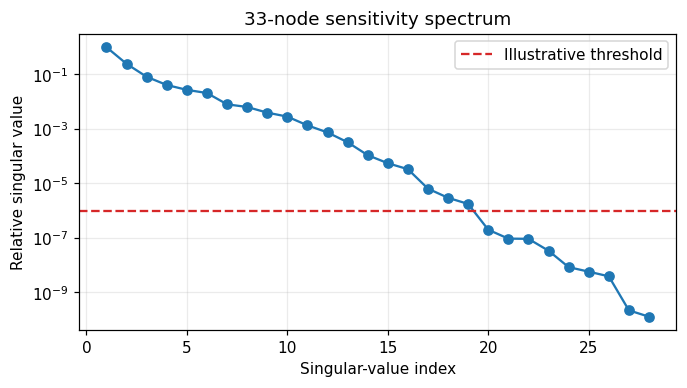

In [20]:
scale33 = np.linalg.norm(data33)
def stacked_response33(depths):
    values = (model33.predict(depths) / scale33).ravel()
    return np.r_[values.real, values.imag]

with threadpool_limits(limits=1, user_api='blas'):
    columns = []
    for i in range(len(x33)):
        delta = np.zeros_like(x33)
        delta[i] = options33.finite_difference_step
        columns.append((stacked_response33(result33.depths+delta) - stacked_response33(result33.depths-delta)) /
                       (2*options33.finite_difference_step))
    jacobian33 = np.column_stack(columns)
    singular_values = np.linalg.svd(jacobian33, compute_uv=False)
effective_rank = np.count_nonzero(singular_values > singular_values[0]*1e-6)
print(f'Jacobian shape {jacobian33.shape}: at least {len(x33)-jacobian33.shape[0]} null directions')
print(f'Singular values above 1e-6 of the largest: {effective_rank} (threshold-dependent)')
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(np.arange(1, len(singular_values)+1), singular_values/singular_values[0], 'o-')
ax.axhline(1e-6, color='tab:red', ls='--', label='Illustrative threshold')
ax.set(xlabel='Singular-value index', ylabel='Relative singular value', title='33-node sensitivity spectrum')
ax.legend()
plt.show()

The 33-node result fits this noise-free, same-mesh example well, but it stopped at the iteration limit with a nonzero update. The sensitivity spectrum also has several very small values, in addition to the five guaranteed null directions. Regularization selects one smooth estimate; neither the small data residual nor the known-target RMSE proves a unique recovery.

## 10. A small repeated-noise check

The paper reports stronger sensitivity to phase perturbations for its examples. We repeat the high-contrast 5% experiment for three fixed seeds, reusing the first run above. Three realizations are **illustrative, not enough for a robust statistical conclusion**. The same seed generates a reproducible amplitude draw followed by a phase draw.

In [21]:
noise_runs = {2026: (results['Amplitude noise'], results['Phase noise'])}
with threadpool_limits(limits=1, user_api='blas'):
    for seed in (2027, 2028):
        amp, phase = noisy_pair(clean_data, 0.05, seed)
        pair = []
        for name, data in [('amplitude', amp), ('phase', phase)]:
            print(f'Running seed {seed}, {name}...', flush=True)
            result = invert_interface(high_model, data, initial, options)
            if result.reason.startswith('line search failed'):
                raise RuntimeError(f'Seed {seed}, {name}: {result.reason}')
            pair.append(result)
        noise_runs[seed] = tuple(pair)

rows = ['| Seed | Amplitude depth RMSE (m) | Phase depth RMSE (m) |', '|--:|--:|--:|']
for seed, (amp_result, phase_result) in noise_runs.items():
    rows.append(f'| {seed} | {depth_rmse(amp_result):.3f} | {depth_rmse(phase_result):.3f} |')
display(Markdown('\n'.join(rows)))
count = sum(depth_rmse(a) > depth_rmse(p) for a, p in noise_runs.values())
display(Markdown(f'Amplitude noise produced larger depth RMSE in **{count} of {len(noise_runs)}** '
                 'draws here. This small, model-dependent sample does not establish a general ranking.'))

Running seed 2027, amplitude...


Running seed 2027, phase...


Running seed 2028, amplitude...


Running seed 2028, phase...


| Seed | Amplitude depth RMSE (m) | Phase depth RMSE (m) |
|--:|--:|--:|
| 2026 | 1.828 | 0.369 |
| 2027 | 2.038 | 0.221 |
| 2028 | 3.861 | 0.443 |

Amplitude noise produced larger depth RMSE in **3 of 3** draws here. This small, model-dependent sample does not establish a general ranking.

## Limitations and next steps

* The paper uses quadratic isoparametric elements and approximately 1500 iterations. Our inversion uses constant straight elements; the 33-node experiment uses only 15 iterations. The cylinder's symmetry-based radial basis is a specialized additional check, not the authors' quadratic BEM.
* The Alabama field data, source calibration and original exact target/topography coordinates are unavailable here. The corresponding field figures are **not reproduced**; all displayed inversion observations are synthetic.
* A single interface, fixed known material properties, one source and one frequency are assumed. Interface depths must be positive relative to the chosen datum as well as below the surface, so interfaces above that datum cannot be modeled. Finite truncation, constant far-field interface extrapolation and 5% complex-modulus damping are modeling choices. The source is a finite patch rather than an ideal point source.
* Same-mesh data are an inverse crime; refined-mesh data still use the same physics and parameterized target. A few noise seeds do not replace full uncertainty analysis, independent solvers, detailed convergence studies, or field validation.